# Probability of Default (PD) Scorecard — Unsecured Personal Loans

**Goal:** build a simple application scorecard that gives every loan applicant a credit score and a probability of default (PD).
**Approach:** classic application-scorecard pipeline — data build → quality checks → EDA → out-of-time split →
cleaning → monotonic Weight of Evidence (WoE) binning and Information Value (IV) → variable selection → logistic regression → scaling to points → validation.

| Stage | What happens |
|---|---|
| 1. Data | Synthetic loan book (INR) with a latent credit-worthiness factor and a *calibrated* default rate |
| 2. Quality & EDA | Missingness, logic checks, distributions, default-rate profiles, correlations |
| 3. Split | Out-of-time: earlier applications for development, later for validation |
| 4. Cleaning | Fit-on-development / apply-to-validation cleaner (no leakage) |
| 5. Binning | Quintile binning, WoE and IV for every candidate |
| 6. Selection | IV filter → correlation pruning → VIF → backward elimination (p-value + sign) |
| 7. Model | Logistic regression on WoE features (statsmodels) |
| 8. Scorecard | Points table, risk bands |
| 9. Validation | AUC / Gini / KS, calibration, lift, PSI/CSI stability |

> All data here is synthetic (no real customer data is used). 

## 1. Import libraries

In [34]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.metrics import roc_auc_score, roc_curve

np.random.seed(100)          # so the results are the same every time
plt.rcParams["figure.figsize"] = (7, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

## 2. Create the dataset
Real loan data is confidential, so I simulate it. A hidden "risk" factor makes variables like
utilisation, enquiries and missed payments move together, the way they do in real life.
Default is then generated from a logistic formula (riskier profile = higher chance of default).

In [35]:
n = 75000
df = pd.DataFrame()

# application date: 2 years of applications
df["app_date"] = pd.to_datetime("2023-01-01") + pd.to_timedelta(np.random.randint(0, 730, n), unit="D")

# hidden risk factor (not given to the model)
risk = np.random.normal(0, 1, n)

# ---- customer profile ----
df["age"] = np.random.normal(37, 11, n).clip(21, 70).round()
df["gender"] = np.random.choice(["M", "F"], n, p=[0.56, 0.44])
df["marital_status"] = np.random.choice(["Single", "Married", "Divorced", "Widowed"], n, p=[0.30, 0.55, 0.10, 0.05])
df["dependents"] = np.random.poisson(1.3, n).clip(0, 5)
df["education"] = np.random.choice(["High School", "Bachelor", "Master", "PhD"], n, p=[0.35, 0.42, 0.19, 0.04])
df["city_tier"] = np.random.choice(["Tier 1", "Tier 2", "Tier 3"], n, p=[0.35, 0.40, 0.25])

# ---- employment and income ----
df["employment_type"] = np.random.choice(["Salaried", "Self-Employed", "Pensioner", "Unemployed"], n, p=[0.64, 0.23, 0.10, 0.03])
income_factor = df["employment_type"].map({"Salaried": 1.0, "Self-Employed": 0.9, "Pensioner": 0.5, "Unemployed": 0.25})
df["monthly_income"] = (np.random.lognormal(np.log(48000), 0.55, n) * income_factor).clip(10000, 600000).round(-2)
df["employment_years"] = np.minimum(np.random.exponential(7, n), df["age"] - 20).clip(0, 40).round()
df["income_verified"] = np.random.choice(["Verified", "Partial", "Not Verified"], n, p=[0.68, 0.20, 0.12])

# ---- loan details ----
df["loan_amount"] = (df["monthly_income"] * np.random.uniform(3, 10, n)).clip(50000, 2500000).round(-2)
df["term_months"] = np.random.choice([12, 24, 36, 48, 60, 72], n)
df["interest_rate"] = (11 + np.random.normal(0, 2.5, n) + 0.6 * risk).clip(8, 24).round(2)

# EMI formula: P * r * (1+r)^n / ((1+r)^n - 1)
r = df["interest_rate"] / 1200
df["emi"] = (df["loan_amount"] * r * (1 + r) ** df["term_months"] / ((1 + r) ** df["term_months"] - 1)).round()
df["emi_to_income"] = (df["emi"] / df["monthly_income"] * 100).round(2)
df["pre_approved"] = np.random.binomial(1, 0.25, n)

# ---- credit bureau information ----
df["credit_history_months"] = (np.random.exponential(70, n) + (df["age"] - 21) * 1.5).clip(6, 360).round()
df["num_accounts"] = np.random.poisson(3, n) + 1
df["credit_utilisation"] = (np.random.beta(2, 4, n) * 100 * np.exp(0.25 * risk)).clip(0, 100).round(1)
df["enquiries_12m"] = np.random.poisson(1.2 * np.exp(0.3 * risk))
df["dpd30_12m"] = np.random.poisson(0.25 * np.exp(0.6 * risk))             # times 30+ days late
df["dpd90_12m"] = np.random.binomial(df["dpd30_12m"], 0.1)                 # times 90+ days late (subset of above)
df["prior_default"] = (np.random.rand(n) < 0.02 + 0.08 * (df["dpd90_12m"] > 0)).astype(int)

# ---- debt burden and savings ----
df["existing_emi"] = (df["monthly_income"] * np.random.beta(2, 7, n) * np.exp(0.2 * risk)).round()
df["debt_to_income"] = (df["existing_emi"] / df["monthly_income"] * 100).round(2)
df["savings"] = (df["monthly_income"] * np.random.gamma(2, 1.5, n)).round()
df["digital_score"] = np.random.normal(60, 20, n).clip(0, 100).round()

# ---- default flag ----
verif_effect = df["income_verified"].map({"Verified": 0, "Partial": 0.25, "Not Verified": 0.55})
emp_effect = df["employment_type"].map({"Salaried": 0, "Self-Employed": 0.2, "Pensioner": 0.15, "Unemployed": 0.6})

logit = (0.9 * df["prior_default"]
         + 0.8 * (df["dpd90_12m"] > 0) + 0.25 * (df["dpd30_12m"] > 0)
         + 0.028 * df["emi_to_income"].clip(0, 90)
         + 0.012 * df["debt_to_income"].clip(0, 150)
         + 0.018 * df["credit_utilisation"]
         + 0.18 * df["enquiries_12m"].clip(upper=6)
         + verif_effect + emp_effect
         - 0.025 * df["employment_years"]
         - 0.08 * (df["savings"] / df["monthly_income"]).clip(0, 12)
         - 0.35 * df["pre_approved"]
         - 0.006 * df["digital_score"]
         + 0.35 * risk + np.random.normal(0, 0.6, n))

# pick the intercept so that the overall default rate is about 12% (simple bisection search)
target_rate = 0.12
low, high = -15, 5
for i in range(50):
    mid = (low + high) / 2
    avg_pd = (1 / (1 + np.exp(-(logit + mid)))).mean()
    if avg_pd > target_rate:
        high = mid
    else:
        low = mid
intercept = (low + high) / 2

pd_true = 1 / (1 + np.exp(-(logit + intercept)))
df["default_flag"] = (np.random.rand(n) < pd_true).astype(int)

print("Shape:", df.shape)
print("Default rate:", round(df["default_flag"].mean() * 100, 2), "%")
df.head()

Shape: (75000, 29)
Default rate: 11.95 %


,app_date,age,gender,marital_status,dependents,education,city_tier,employment_type,monthly_income,employment_years,...,credit_utilisation,enquiries_12m,dpd30_12m,dpd90_12m,prior_default,existing_emi,debt_to_income,savings,digital_score,default_flag
0,2024-06-04,61.0,F,Single,3,Master,Tier 1,Self-Employed,35600.0,19.0,...,14.7,1,0,0,0,13002.0,36.52,28598.0,68.0,0
1,2023-03-21,21.0,M,Married,1,Bachelor,Tier 2,Salaried,41700.0,1.0,...,42.5,1,0,0,0,4919.0,11.80,64393.0,54.0,0
2,2023-12-17,33.0,F,Married,1,High School,Tier 2,Self-Employed,67800.0,13.0,...,12.4,1,0,0,0,18577.0,27.40,53460.0,90.0,0
3,2023-02-23,33.0,F,Single,1,Master,Tier 2,Salaried,25100.0,0.0,...,73.6,4,0,0,0,3167.0,12.62,208967.0,57.0,0
4,2024-08-01,33.0,F,Single,1,High School,Tier 3,Salaried,76000.0,0.0,...,61.9,3,0,0,0,19802.0,26.06,88040.0,47.0,0


### Add some real-world messiness
Real data always has missing values, duplicate rows and inconsistent text. I add a few so the cleaning step has something to do.

In [36]:
# missing values in some columns
missing_share = {"monthly_income": 0.02, "employment_years": 0.03, "savings": 0.05,
                 "prior_default": 0.01, "income_verified": 0.04}
for col, share in missing_share.items():
    rows = np.random.choice(df.index, int(n * share), replace=False)
    df.loc[rows, col] = np.nan

# inconsistent labels (lower case salaried)
rows = np.random.choice(df.index[df["employment_type"] == "Salaried"], 50, replace=False)
df.loc[rows, "employment_type"] = "salaried"

# a few duplicate rows
df = pd.concat([df, df.sample(15, random_state=1)]).reset_index(drop=True)
print("Rows after adding duplicates:", len(df))

Rows after adding duplicates: 75015


## 3. Data quality checks

prior_default       1.0
monthly_income      2.0
employment_years    3.0
income_verified     4.0
savings             5.0
dtype: float64


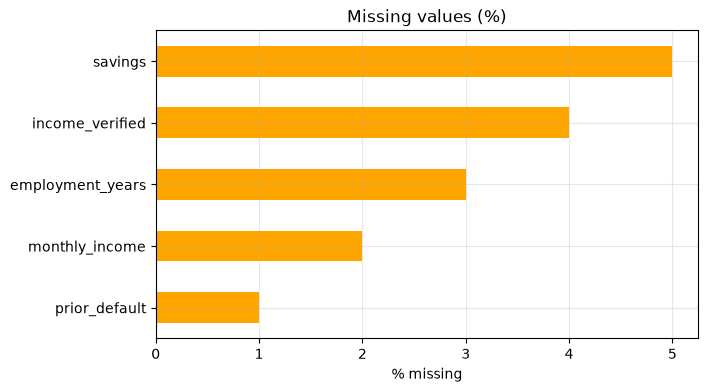

In [37]:
# 3.1 missing values
missing = (df.isnull().mean() * 100).round(2)
missing = missing[missing > 0].sort_values()
print(missing)

missing.plot(kind="barh", color="orange")
plt.title("Missing values (%)")
plt.xlabel("% missing")
plt.show()

In [38]:
# 3.2 duplicates and label problems
print("Duplicate rows:", df.duplicated().sum())
print("\nEmployment types found:")
print(df["employment_type"].value_counts())

# 3.3 simple logic checks
print("\nAge below 18:", (df["age"] < 18).sum())
print("Utilisation above 100%:", (df["credit_utilisation"] > 100).sum())
print("EMI <= 0:", (df["emi"] <= 0).sum())

Duplicate rows: 15

Employment types found:
employment_type
Salaried         47878
Self-Employed    17220
Pensioner         7584
Unemployed        2283
salaried            50
Name: count, dtype: int64

Age below 18: 0
Utilisation above 100%: 0
EMI <= 0: 0


## 4. Exploratory data analysis

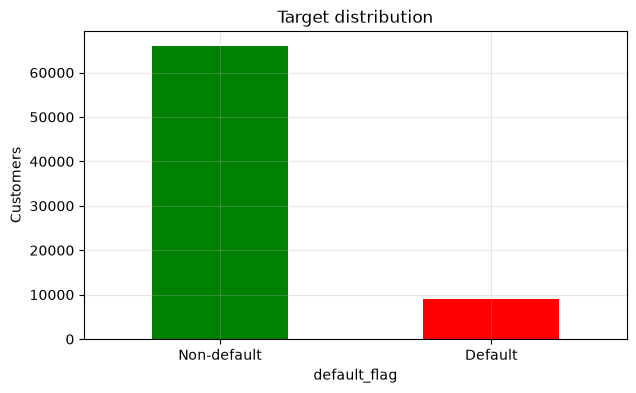

In [39]:
# 4.1 target balance
df["default_flag"].value_counts().plot(kind="bar", color=["green", "red"])
plt.xticks([0, 1], ["Non-default", "Default"], rotation=0)
plt.title("Target distribution")
plt.ylabel("Customers")
plt.show()

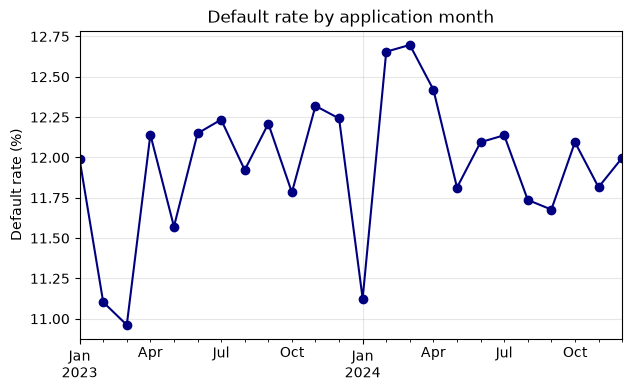

In [40]:
# 4.2 default rate across the months
monthly_dr = df.groupby(df["app_date"].dt.to_period("M"))["default_flag"].mean() * 100
monthly_dr.plot(marker="o", color="navy")
plt.title("Default rate by application month")
plt.ylabel("Default rate (%)")
plt.xlabel("")
plt.show()

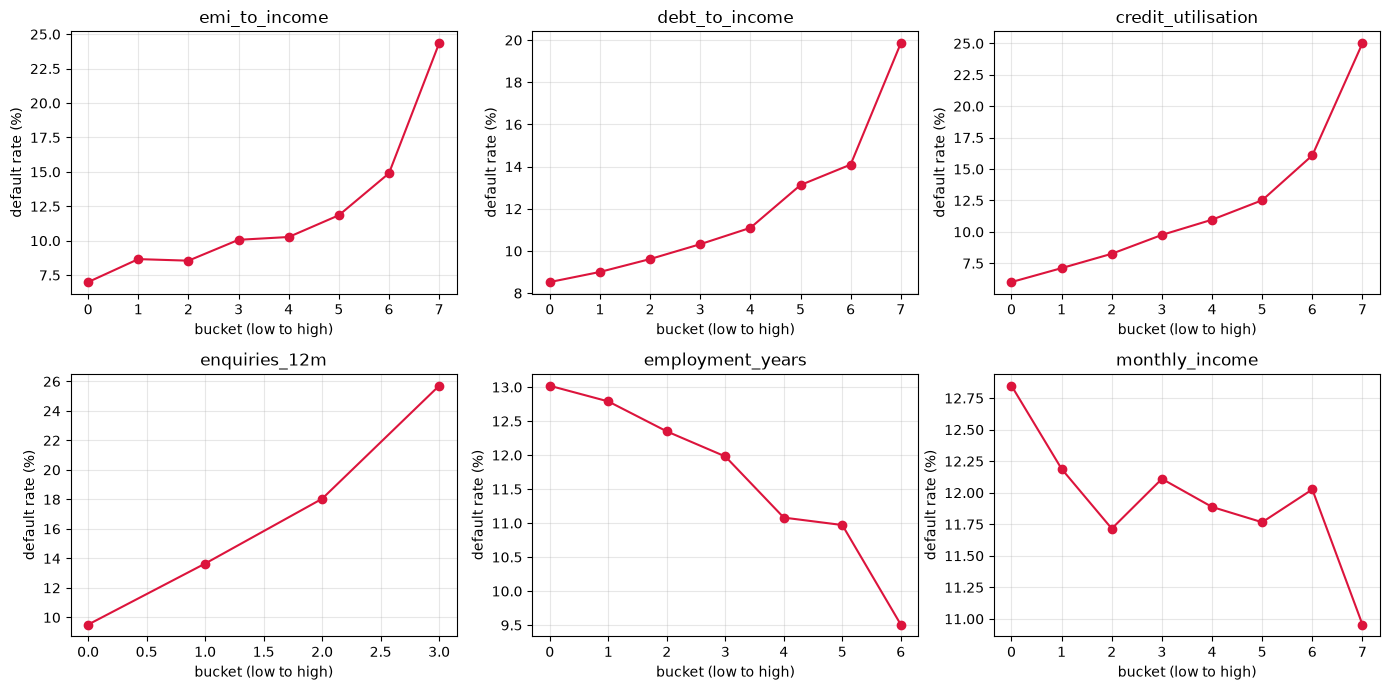

In [41]:
# 4.3 default rate by bucket for a few important variables
# idea: if a variable is useful, default rate should clearly move as the variable increases
plot_vars = ["emi_to_income", "debt_to_income", "credit_utilisation", "enquiries_12m", "employment_years", "monthly_income"]

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.ravel(), plot_vars):
    buckets = pd.qcut(df[col], 8, duplicates="drop")
    rate = df.groupby(buckets, observed=True)["default_flag"].mean() * 100
    ax.plot(range(len(rate)), rate.values, marker="o", color="crimson")
    ax.set_title(col)
    ax.set_xlabel("bucket (low to high)")
    ax.set_ylabel("default rate (%)")
plt.tight_layout()
plt.show()

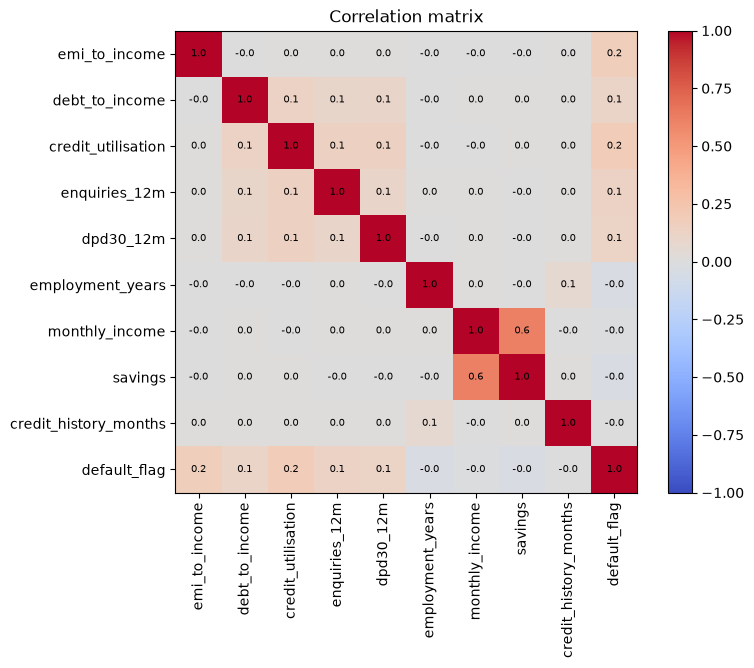

In [42]:
# 4.4 correlation between key numeric variables
corr_cols = ["emi_to_income", "debt_to_income", "credit_utilisation", "enquiries_12m", "dpd30_12m",
             "employment_years", "monthly_income", "savings", "credit_history_months", "default_flag"]
corr = df[corr_cols].corr()

plt.figure(figsize=(8, 6))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar()
plt.xticks(range(len(corr_cols)), corr_cols, rotation=90)
plt.yticks(range(len(corr_cols)), corr_cols)
for i in range(len(corr_cols)):
    for j in range(len(corr_cols)):
        plt.text(j, i, round(corr.iloc[i, j], 1), ha="center", va="center", fontsize=7)
plt.title("Correlation matrix")
plt.grid(False)
plt.show()

## 5. Development and validation split
I split by **time**: older applications (before April 2024) to build the model and newer applications to test it.
This is closer to real life, where a model built on the past is used on future customers.

In [43]:
# first do the simple cleaning that does not depend on any statistics
df = df.drop_duplicates()
df["employment_type"] = df["employment_type"].str.upper()
for col in ["gender", "marital_status", "education", "city_tier", "income_verified"]:
    df[col] = df[col].str.upper()

dev = df[df["app_date"] < "2024-04-01"].copy()
val = df[df["app_date"] >= "2024-04-01"].copy()

print("Development rows:", len(dev), "| default rate:", round(dev["default_flag"].mean() * 100, 2), "%")
print("Validation rows :", len(val), "| default rate:", round(val["default_flag"].mean() * 100, 2), "%")

Development rows: 46908 | default rate: 11.94 %
Validation rows : 28092 | default rate: 11.98 %


## 6. Fill missing values and treat outliers
Medians / modes / caps are calculated on the **development data only** and then reused for validation,
so no information from the validation sample leaks into the model.

In [44]:
cat_cols = ["gender", "marital_status", "education", "city_tier", "employment_type", "income_verified"]
num_cols = [c for c in dev.columns if c not in cat_cols + ["app_date", "default_flag"]]

# fill numeric with median, categorical with most frequent value
for col in num_cols:
    fill_value = dev[col].median()
    dev[col] = dev[col].fillna(fill_value)
    val[col] = val[col].fillna(fill_value)

for col in cat_cols:
    fill_value = dev[col].mode()[0]
    dev[col] = dev[col].fillna(fill_value)
    val[col] = val[col].fillna(fill_value)

# cap extreme values at 1st and 99th percentile of the development data
cap_cols = ["monthly_income", "loan_amount", "emi", "emi_to_income", "existing_emi",
            "debt_to_income", "savings"]
for col in cap_cols:
    lower = dev[col].quantile(0.01)
    upper = dev[col].quantile(0.99)
    dev[col] = dev[col].clip(lower, upper)
    val[col] = val[col].clip(lower, upper)

print("Missing values left (dev):", dev.isnull().sum().sum())
print("Missing values left (val):", val.isnull().sum().sum())

Missing values left (dev): 0
Missing values left (val): 0


## 7. Binning, WoE and IV

* **Binning:** numeric variables are cut into 5 equal-sized groups (quintiles). Variables with only a few distinct values
  (like number of late payments) and text variables are used as they are.
* **WoE** = ln( % of good customers in bin / % of bad customers in bin ). Positive WoE = safer group, negative = riskier group.
* **IV** = sum of (%good - %bad) x WoE. It tells how well a variable separates good from bad.

| IV | Meaning |
|---|---|
| below 0.02 | useless |
| 0.02 - 0.1 | weak |
| 0.1 - 0.3 | medium |
| 0.3 - 0.5 | strong |
| above 0.5 | too good, check for leakage |

In [45]:
def get_groups(series, edges):
    # numeric variables: put each value in its bin number, text/few-value variables: keep the value itself
    if edges is None:
        return series
    return pd.cut(series, bins=edges, labels=False)


def woe_iv_table(groups, target):
    # count goods and bads in each bin
    t = pd.crosstab(groups, target)
    t.columns = ["good", "bad"]
    t["total"] = t["good"] + t["bad"]
    t["bad_rate"] = t["bad"] / t["total"]
    # add 0.5 to avoid log(0) / divide by zero in tiny bins
    pct_good = (t["good"] + 0.5) / (t["good"].sum() + 0.5)
    pct_bad = (t["bad"] + 0.5) / (t["bad"].sum() + 0.5)
    t["woe"] = np.log(pct_good / pct_bad)
    t["iv"] = (pct_good - pct_bad) * t["woe"]
    return t


bin_edges = {}      # stores the bin edges of every variable
woe_tables = {}     # stores the WoE table of every variable
iv_values = {}      # stores the IV of every variable

features = [c for c in dev.columns if c not in ["app_date", "default_flag"]]

for col in features:
    # decide if the variable needs to be cut into bins
    if dev[col].dtype == "object" or dev[col].nunique() <= 10:
        edges = None
    else:
        cuts = np.unique(np.quantile(dev[col], [0.2, 0.4, 0.6, 0.8]))
        edges = [-np.inf] + list(cuts) + [np.inf]

    groups = get_groups(dev[col], edges)
    table = woe_iv_table(groups, dev["default_flag"])

    bin_edges[col] = edges
    woe_tables[col] = table
    iv_values[col] = table["iv"].sum()

iv_df = pd.DataFrame({"variable": list(iv_values.keys()), "IV": list(iv_values.values())})
iv_df = iv_df.sort_values("IV", ascending=False).reset_index(drop=True)
iv_df

,variable,IV
0,credit_utilisation,0.252450
1,emi_to_income,0.201242
2,term_months,0.179636
3,enquiries_12m,0.142301
4,dpd30_12m,0.120127
5,debt_to_income,0.091678
6,emi,0.089779
7,dpd90_12m,0.053024
8,existing_emi,0.031910
9,interest_rate,0.029184


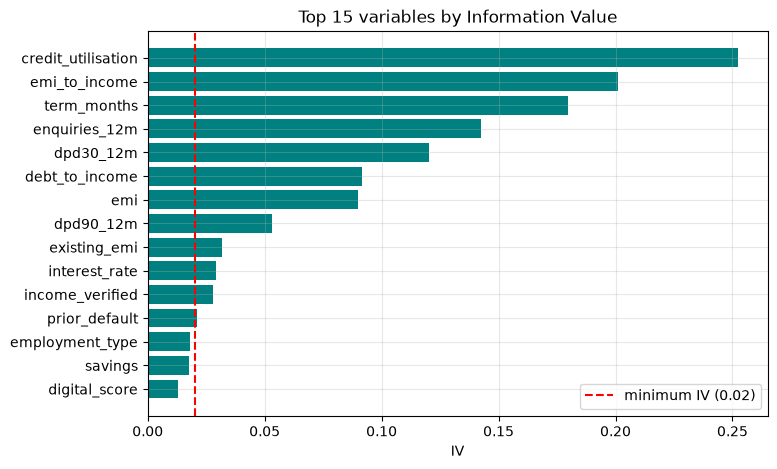

In [46]:
# IV chart
top = iv_df.head(15).iloc[::-1]
plt.figure(figsize=(8, 5))
plt.barh(top["variable"], top["IV"], color="teal")
plt.axvline(0.02, color="red", linestyle="--", label="minimum IV (0.02)")
plt.title("Top 15 variables by Information Value")
plt.xlabel("IV")
plt.legend()
plt.show()

In [47]:
# look at the bins of the best variable
best_var = iv_df.loc[0, "variable"]
print("Bins for:", best_var)
woe_tables[best_var].round(3)

Bins for: credit_utilisation


,good,bad,total,bad_rate,woe,iv
credit_utilisation,,,,,,
0,8847,600,9447,0.064,0.692,0.074
1,8622,770,9392,0.082,0.417,0.030
2,8384,940,9324,0.101,0.190,0.007
3,8173,1236,9409,0.131,-0.110,0.003
4,7282,2054,9336,0.220,-0.733,0.140


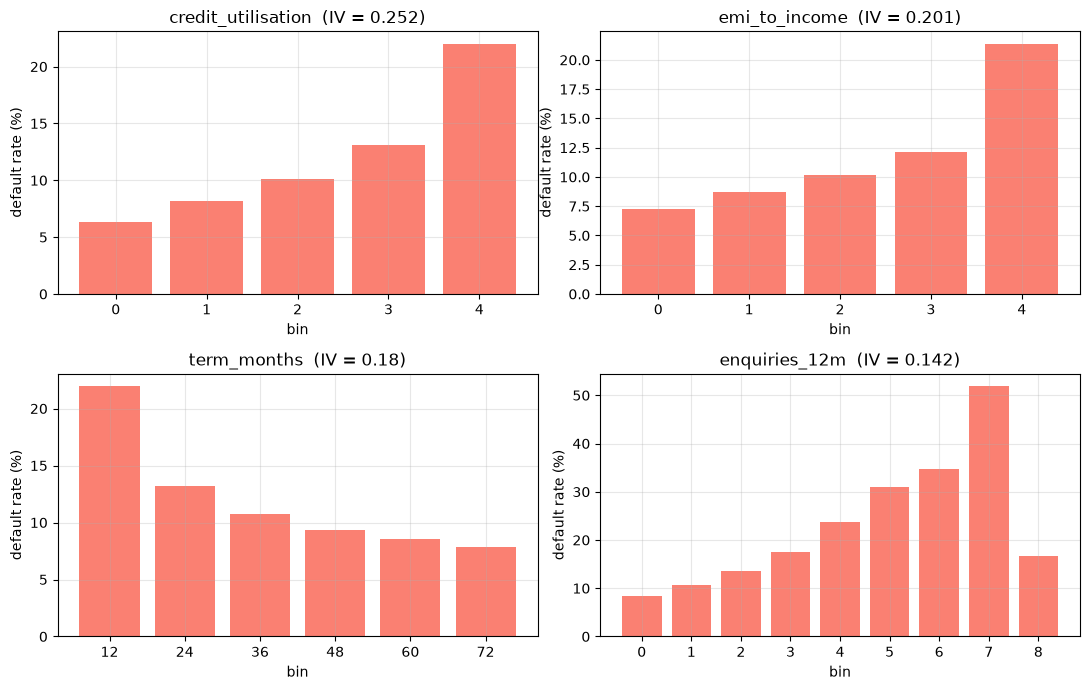

In [48]:
# bad rate per bin for the top 4 variables (a good variable shows a clear trend)
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, col in zip(axes.ravel(), iv_df["variable"].head(4)):
    t = woe_tables[col]
    ax.bar(range(len(t)), t["bad_rate"] * 100, color="salmon")
    ax.set_xticks(range(len(t)))
    ax.set_xticklabels(t.index, rotation=0)
    ax.set_title(col + "  (IV = " + str(round(iv_values[col], 3)) + ")")
    ax.set_ylabel("default rate (%)")
    ax.set_xlabel("bin")
plt.tight_layout()
plt.show()

## 8. Variable selection
Rules used (in this order):
1. **IV filter:** keep variables with IV between 0.02 and 0.5
2. **Correlation pruning:** if two variables are highly correlated (above 0.7), keep only the one with higher IV
3. **VIF check:** repeatedly remove the variable with the highest VIF until every VIF is 5 or below
4. **Backward elimination:** fit the model, then remove one variable at a time if its coefficient has the wrong sign or its p-value is above 0.05

First I convert the data to WoE values.

In [49]:
def to_woe(data, col):
    groups = get_groups(data[col], bin_edges[col])
    return groups.map(woe_tables[col]["woe"]).fillna(0).astype(float)


# step 1: IV filter
selected = iv_df[(iv_df["IV"] >= 0.02) & (iv_df["IV"] <= 0.5)]["variable"].tolist()
print("After IV filter:", len(selected), "variables")

# WoE dataframe for the shortlisted variables
woe_dev = pd.DataFrame({col: to_woe(dev, col) for col in selected})

# step 2: remove highly correlated variables (list is already sorted by IV)
corr_matrix = woe_dev.corr()
keep = []
for col in selected:
    too_similar = False
    for k in keep:
        if abs(corr_matrix.loc[col, k]) > 0.7:
            too_similar = True
    if not too_similar:
        keep.append(col)

print("After correlation check:", len(keep), "variables")
print("Removed:", [c for c in selected if c not in keep])

After IV filter: 12 variables
After correlation check: 11 variables
Removed: ['term_months']


In [50]:
# step 3: VIF (Variance Inflation Factor) check
# VIF shows how well one variable can be predicted from all the other variables.
# VIF = 1 means no overlap, above 5 means the variable is mostly repeating information already in the model.
# Correlation (step 2) only compares two variables at a time, VIF looks at all of them together.
y_dev = dev["default_flag"]
y_val = val["default_flag"]

vif_vars = keep.copy()
while True:
    # VIF needs a constant column, it sits in column 0, so variable number i is in column i + 1
    X = sm.add_constant(woe_dev[vif_vars])
    vif = pd.Series([variance_inflation_factor(X.values, i + 1) for i in range(len(vif_vars))],
                    index=vif_vars)

    if vif.max() > 5:
        worst = vif.idxmax()
        print("Removing", worst, "(VIF =", round(vif.max(), 2), ")")
        vif_vars.remove(worst)
    else:
        break

# final VIF table of the variables that are left
print("\nVIF of remaining variables:")
print(vif.round(2).sort_values(ascending=False))
print("\nAfter VIF check:", len(vif_vars), "variables")


VIF of remaining variables:
existing_emi          3.54
emi                   3.50
debt_to_income        2.59
emi_to_income         2.57
dpd30_12m             1.16
dpd90_12m             1.13
credit_utilisation    1.04
enquiries_12m         1.03
interest_rate         1.02
prior_default         1.01
income_verified       1.00
dtype: float64

After VIF check: 11 variables


In [51]:
# step 4: backward elimination using statsmodels
# Fit the logistic regression, then remove ONE variable at a time and refit:
#   (a) first remove any variable with a positive coefficient (wrong sign)
#       -> WoE is higher for safer customers, so a sensible coefficient must be negative
#   (b) if all signs are fine, remove the variable with the highest p-value, as long as it is above 0.05
# Stop when every variable has the right sign and a p-value of 0.05 or below.
final_vars = vif_vars.copy()
while True:
    X = sm.add_constant(woe_dev[final_vars])
    model = sm.Logit(y_dev, X).fit(disp=0)

    coefs = model.params.drop("const")       # coefficient of each variable (without the intercept)
    pvalues = model.pvalues.drop("const")    # p-value of each variable

    if coefs.max() > 0:
        worst = coefs.idxmax()
        print("Removing", worst, "(wrong sign)")
        final_vars.remove(worst)
    elif pvalues.max() > 0.05:
        worst = pvalues.idxmax()
        print("Removing", worst, "(p-value =", round(pvalues.max(), 4), ")")
        final_vars.remove(worst)
    else:
        break

print("\nFinal variables:", final_vars)

Removing existing_emi (wrong sign)
Removing emi (p-value = 0.7128 )

Final variables: ['credit_utilisation', 'emi_to_income', 'enquiries_12m', 'dpd30_12m', 'debt_to_income', 'dpd90_12m', 'interest_rate', 'income_verified', 'prior_default']


## 9. Logistic regression model
The model is fitted with **statsmodels** so that standard errors and p-values are available.
log-odds of default = intercept + b1 x WoE1 + b2 x WoE2 + ...

In [52]:
# full statsmodels output (coefficients, standard errors, p-values, confidence intervals)
print(model.summary())

coef_table = pd.DataFrame({"variable": final_vars,
                           "coefficient": model.params[final_vars].values,
                           "std_error": model.bse[final_vars].values,
                           "p_value": model.pvalues[final_vars].values})
coef_table["odds_ratio"] = np.exp(coef_table["coefficient"])
print("\nIntercept:", round(model.params["const"], 4))
coef_table.round(4)

                           Logit Regression Results                           
Dep. Variable:           default_flag   No. Observations:                46908
Model:                          Logit   Df Residuals:                    46898
Method:                           MLE   Df Model:                            9
Date:                Sun, 22 Nov 2026   Pseudo R-squ.:                  0.1105
Time:                        08:53:11   Log-Likelihood:                -15258.
converged:                       True   LL-Null:                       -17154.
Covariance Type:            nonrobust   LLR p-value:                     0.000
                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
const                 -1.9999      0.016   -128.508      0.000      -2.030      -1.969
credit_utilisation    -0.8601      0.030    -28.975      0.000      -0.918      -0.802
emi_to_income       

,variable,coefficient,std_error,p_value,odds_ratio
0,credit_utilisation,-0.8601,0.0297,0.0,0.4231
1,emi_to_income,-1.0717,0.0325,0.0,0.3424
2,enquiries_12m,-0.7844,0.0384,0.0,0.4564
3,dpd30_12m,-0.5989,0.0444,0.0,0.5494
4,debt_to_income,-0.7291,0.0489,0.0,0.4823
5,dpd90_12m,-0.5727,0.0630,0.0,0.5640
6,interest_rate,-0.4339,0.0881,0.0,0.6480
7,income_verified,-1.1636,0.0862,0.0,0.3124
8,prior_default,-0.9574,0.0943,0.0,0.3839


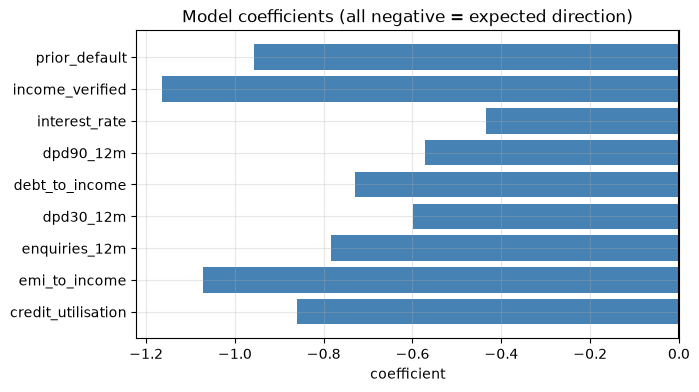

In [53]:
# coefficient chart
plt.barh(coef_table["variable"], coef_table["coefficient"], color="steelblue")
plt.axvline(0, color="black")
plt.title("Model coefficients (all negative = expected direction)")
plt.xlabel("coefficient")
plt.show()

In [54]:
# predicted PD for development and validation
woe_dev = pd.DataFrame({col: to_woe(dev, col) for col in final_vars})
woe_val = pd.DataFrame({col: to_woe(val, col) for col in final_vars})

dev["pd"] = model.predict(sm.add_constant(woe_dev, has_constant="add"))
val["pd"] = model.predict(sm.add_constant(woe_val, has_constant="add"))

print("Average predicted PD (dev):", round(dev["pd"].mean() * 100, 2), "%  | actual:", round(y_dev.mean() * 100, 2), "%")
print("Average predicted PD (val):", round(val["pd"].mean() * 100, 2), "%  | actual:", round(y_val.mean() * 100, 2), "%")

Average predicted PD (dev): 11.94 %  | actual: 11.94 %
Average predicted PD (val): 11.96 %  | actual: 11.98 %


## 10. Scorecard
The log-odds are converted into points with the usual scaling:

* Base score = 600 at good:bad odds of 50:1
* PDO (points to double the odds) = 20
* Factor = PDO / ln(2)
* Offset = Base score - Factor x ln(Base odds)

Points for each bin = -(coefficient x WoE + intercept / n) x Factor + Offset / n, where n is the number of variables.
The minus sign is there because the model predicts **bad**, while a higher score should mean **good**.

In [55]:
base_score = 600
base_odds = 50
pdo = 20

factor = pdo / np.log(2)
offset = base_score - factor * np.log(base_odds)
n_vars = len(final_vars)
intercept = model.params["const"]

print("Factor:", round(factor, 3), "| Offset:", round(offset, 3))

# points for every bin of every final variable
points = {}
scorecard_rows = []
for i, col in enumerate(final_vars):
    t = woe_tables[col]
    pts = -(coefs[col] * t["woe"] + intercept / n_vars) * factor + offset / n_vars
    points[col] = pts
    for bin_name in t.index:
        scorecard_rows.append([col, bin_name, round(t.loc[bin_name, "bad_rate"] * 100, 1),
                               round(t.loc[bin_name, "woe"], 3), round(pts[bin_name], 1)])

scorecard = pd.DataFrame(scorecard_rows, columns=["variable", "bin", "bad_rate_%", "woe", "points"])
scorecard

Factor: 28.854 | Offset: 487.123


,variable,bin,bad_rate_%,woe,points
0,credit_utilisation,0,6.4,0.692,77.7
1,credit_utilisation,1,8.2,0.417,70.9
2,credit_utilisation,2,10.1,0.190,65.2
3,credit_utilisation,3,13.1,-0.110,57.8
4,credit_utilisation,4,22.0,-0.733,42.4
5,emi_to_income,0,7.3,0.548,77.5
6,emi_to_income,1,8.7,0.352,71.4
7,emi_to_income,2,10.2,0.177,66.0
8,emi_to_income,3,12.2,-0.021,59.9
9,emi_to_income,4,21.4,-0.696,39.0


In [56]:
# score for each customer = sum of points from every variable
def calculate_score(data):
    total = pd.Series(0.0, index=data.index)
    for col in final_vars:
        groups = get_groups(data[col], bin_edges[col])
        total = total + groups.map(points[col]).fillna(offset / n_vars)
    return total.round().astype(int)


dev["score"] = calculate_score(dev)
val["score"] = calculate_score(val)

print("Score range (dev):", dev["score"].min(), "to", dev["score"].max())
print("Correlation between score and PD:", round(dev["score"].corr(dev["pd"]), 3), "(should be strongly negative)")

Score range (dev): 428 to 607
Correlation between score and PD: -0.936 (should be strongly negative)


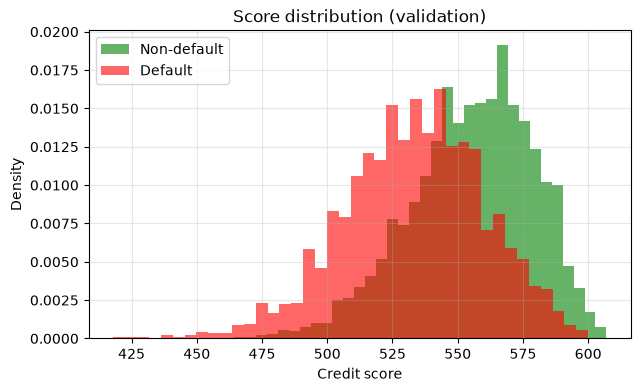

In [57]:
# score distribution for good and bad customers
plt.hist(val.loc[val["default_flag"] == 0, "score"], bins=40, alpha=0.6, color="green", label="Non-default", density=True)
plt.hist(val.loc[val["default_flag"] == 1, "score"], bins=40, alpha=0.6, color="red", label="Default", density=True)
plt.title("Score distribution (validation)")
plt.xlabel("Credit score")
plt.ylabel("Density")
plt.legend()
plt.show()

### Risk bands
Customers are grouped into 5 bands using score cut-offs from the development sample (each band has roughly 20% of customers).
The same cut-offs are used for validation.

In [58]:
cutoffs = np.quantile(dev["score"], [0.2, 0.4, 0.6, 0.8])
band_edges = [-np.inf] + list(cutoffs) + [np.inf]
band_names = ["E - Very High Risk", "D - High Risk", "C - Medium Risk", "B - Low Risk", "A - Very Low Risk"]

dev["band"] = pd.cut(dev["score"], bins=band_edges, labels=band_names, right=False)
val["band"] = pd.cut(val["score"], bins=band_edges, labels=band_names, right=False)

def band_summary(data):
    summary = data.groupby("band", observed=True).agg(customers=("default_flag", "count"),
                                                       defaults=("default_flag", "sum"),
                                                       actual_default_rate=("default_flag", "mean"),
                                                       avg_pd=("pd", "mean"),
                                                       min_score=("score", "min"),
                                                       max_score=("score", "max"))
    return summary.round(4)

print("Development")
display(band_summary(dev))
print("Validation")
display(band_summary(val))

Development


,customers,defaults,actual_default_rate,avg_pd,min_score,max_score
band,,,,,,
E - Very High Risk,9163,2615,0.2854,0.2848,428,531
D - High Risk,9006,1271,0.1411,0.1390,532,547
C - Medium Risk,9210,824,0.0895,0.0898,548,560
B - Low Risk,9789,568,0.0580,0.0590,561,574
A - Very Low Risk,9740,322,0.0331,0.0343,575,607


Validation


,customers,defaults,actual_default_rate,avg_pd,min_score,max_score
band,,,,,,
E - Very High Risk,5446,1545,0.2837,0.2864,418,531
D - High Risk,5468,789,0.1443,0.1389,532,547
C - Medium Risk,5522,507,0.0918,0.0901,548,560
B - Low Risk,5862,333,0.0568,0.0588,561,574
A - Very Low Risk,5794,191,0.0330,0.0343,575,607


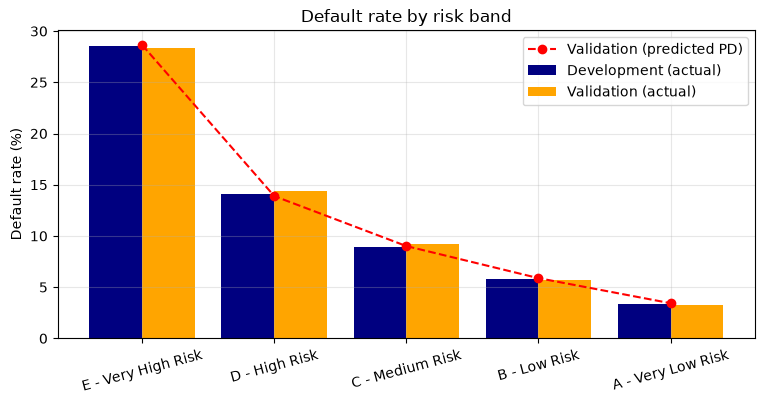

In [59]:
# actual vs predicted default rate in each band
b_dev = band_summary(dev)
b_val = band_summary(val)
x = np.arange(len(band_names))

plt.figure(figsize=(9, 4))
plt.bar(x - 0.2, b_dev["actual_default_rate"] * 100, width=0.4, label="Development (actual)", color="navy")
plt.bar(x + 0.2, b_val["actual_default_rate"] * 100, width=0.4, label="Validation (actual)", color="orange")
plt.plot(x, b_val["avg_pd"] * 100, "r--o", label="Validation (predicted PD)")
plt.xticks(x, band_names, rotation=15)
plt.ylabel("Default rate (%)")
plt.title("Default rate by risk band")
plt.legend()
plt.show()

## 11. Model validation
* **AUC** - how well the model ranks bad customers above good ones (0.5 = random, 1 = perfect)
* **Gini** = 2 x AUC - 1
* **KS** - maximum gap between the cumulative distribution of good and bad customers
* **Calibration** - does the predicted PD match the actual default rate?
* **Lift** - how many times riskier than average is each decile of customers, and how many defaults are caught in the riskiest deciles
* **PSI** - checks whether the score distribution has shifted between development and validation
* **CSI** - the same check for every variable in the model, to see which variable caused any shift

In [60]:
def ks_value(y, p):
    fpr, tpr, _ = roc_curve(y, p)
    return (tpr - fpr).max()

auc_dev = roc_auc_score(y_dev, dev["pd"])
auc_val = roc_auc_score(y_val, val["pd"])

results = pd.DataFrame({
    "Development": [auc_dev, 2 * auc_dev - 1, ks_value(y_dev, dev["pd"])],
    "Validation": [auc_val, 2 * auc_val - 1, ks_value(y_val, val["pd"])]
}, index=["AUC", "Gini", "KS"])
results.round(4)

,Development,Validation
AUC,0.7356,0.7335
Gini,0.4712,0.4670
KS,0.3492,0.3501


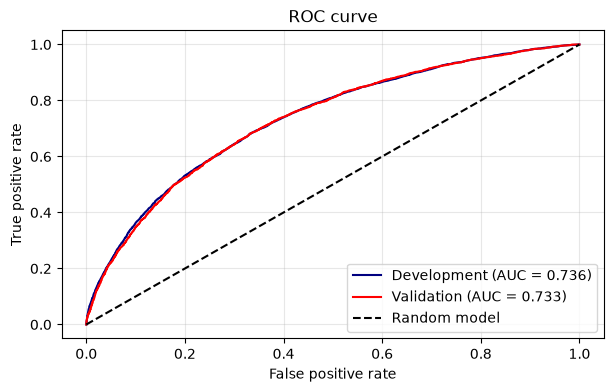

In [61]:
# ROC curve
for name, data, colour in [("Development", dev, "navy"), ("Validation", val, "red")]:
    fpr, tpr, _ = roc_curve(data["default_flag"], data["pd"])
    plt.plot(fpr, tpr, color=colour, label=name + " (AUC = " + str(round(roc_auc_score(data["default_flag"], data["pd"]), 3)) + ")")
plt.plot([0, 1], [0, 1], "k--", label="Random model")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC curve")
plt.legend()
plt.show()

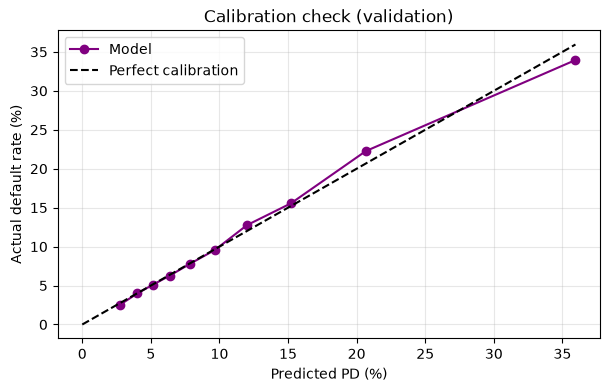

In [62]:
# calibration: average predicted PD vs actual default rate in 10 PD groups (validation)
val["pd_group"] = pd.qcut(val["pd"], 10, labels=False, duplicates="drop")
calib = val.groupby("pd_group")[["pd", "default_flag"]].mean() * 100

plt.plot(calib["pd"], calib["default_flag"], "o-", color="purple", label="Model")
plt.plot([0, calib["pd"].max()], [0, calib["pd"].max()], "k--", label="Perfect calibration")
plt.xlabel("Predicted PD (%)")
plt.ylabel("Actual default rate (%)")
plt.title("Calibration check (validation)")
plt.legend()
plt.show()

In [63]:
# PSI: compare the share of customers in each score band for dev vs validation
dev_share = dev["band"].value_counts(normalize=True).reindex(band_names)
val_share = val["band"].value_counts(normalize=True).reindex(band_names)

psi = ((val_share - dev_share) * np.log(val_share / dev_share)).sum()
print("Score PSI:", round(psi, 4))
print("Rule of thumb: below 0.10 = stable, 0.10 to 0.25 = small shift, above 0.25 = big shift")

Score PSI: 0.0001
Rule of thumb: below 0.10 = stable, 0.10 to 0.25 = small shift, above 0.25 = big shift


Overall default rate (validation): 11.98 %


,customers,defaults,default_rate,lift,cum_defaults_captured_%
decile,,,,,
1,2810,954,0.340,2.834,28.351
2,2809,625,0.222,1.857,46.924
3,2809,437,0.156,1.299,59.911
4,2809,358,0.127,1.064,70.550
5,2809,269,0.096,0.799,78.544
6,2809,219,0.078,0.651,85.052
7,2809,176,0.063,0.523,90.282
8,2809,143,0.051,0.425,94.532
9,2809,112,0.040,0.333,97.860


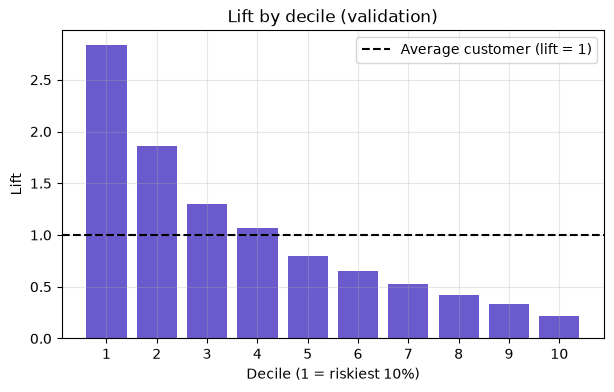

In [64]:
# Lift: sort the validation customers from riskiest to safest (highest PD first)
# and cut them into 10 equal groups (decile 1 = riskiest 10%).
# lift = default rate in the decile / overall default rate
# e.g. lift of 3 means that decile defaults 3 times more than an average customer.
val_sorted = val.sort_values("pd", ascending=False).copy()
val_sorted["decile"] = pd.qcut(np.arange(len(val_sorted)), 10, labels=False) + 1

overall_rate = val_sorted["default_flag"].mean()

lift_table = val_sorted.groupby("decile").agg(customers=("default_flag", "count"),
                                              defaults=("default_flag", "sum"),
                                              default_rate=("default_flag", "mean"))
lift_table["lift"] = lift_table["default_rate"] / overall_rate

# share of all defaults caught up to this decile (cumulative capture rate)
lift_table["cum_defaults_captured_%"] = lift_table["defaults"].cumsum() / lift_table["defaults"].sum() * 100

print("Overall default rate (validation):", round(overall_rate * 100, 2), "%")
display(lift_table.round(3))

# lift chart
plt.bar(lift_table.index, lift_table["lift"], color="slateblue")
plt.axhline(1, color="black", linestyle="--", label="Average customer (lift = 1)")
plt.xticks(lift_table.index)
plt.xlabel("Decile (1 = riskiest 10%)")
plt.ylabel("Lift")
plt.title("Lift by decile (validation)")
plt.legend()
plt.show()

In [65]:
# CSI (Characteristic Stability Index): PSI calculated for each model variable
# For every variable, compare the share of customers in each bin for development vs validation.
# Same rule of thumb as PSI: below 0.10 = stable, 0.10 to 0.25 = small shift, above 0.25 = big shift.
def csi_value(col):
    dev_groups = get_groups(dev[col], bin_edges[col])
    val_groups = get_groups(val[col], bin_edges[col])

    dev_pct = dev_groups.value_counts(normalize=True)
    val_pct = val_groups.value_counts(normalize=True)

    # put both on the same list of bins, a bin missing in one sample gets a tiny share to avoid log(0)
    all_bins = dev_pct.index.union(val_pct.index)
    dev_pct = dev_pct.reindex(all_bins).fillna(0.0001)
    val_pct = val_pct.reindex(all_bins).fillna(0.0001)

    return ((val_pct - dev_pct) * np.log(val_pct / dev_pct)).sum()


csi_df = pd.DataFrame({"variable": final_vars, "CSI": [csi_value(col) for col in final_vars]})
csi_df["status"] = np.where(csi_df["CSI"] < 0.10, "stable",
                            np.where(csi_df["CSI"] < 0.25, "small shift", "big shift"))
csi_df.sort_values("CSI", ascending=False).reset_index(drop=True).round(4)

,variable,CSI,status
0,interest_rate,0.0004,stable
1,dpd30_12m,0.0003,stable
2,enquiries_12m,0.0002,stable
3,dpd90_12m,0.0001,stable
4,debt_to_income,0.0001,stable
5,emi_to_income,0.0001,stable
6,credit_utilisation,0.0001,stable
7,income_verified,0.0001,stable
8,prior_default,0.0000,stable


## 12. Save outputs and conclusion

In [66]:
scorecard.to_csv("scorecard_points.csv", index=False)
iv_df.to_csv("iv_ranking.csv", index=False)
print("Saved scorecard_points.csv and iv_ranking.csv")

Saved scorecard_points.csv and iv_ranking.csv


### Conclusion
* A logistic regression scorecard was built using WoE-transformed variables and converted to a 600-point scale (PDO = 20).
* Variables were selected with an IV filter, correlation pruning, a VIF check and backward elimination (sign + p-value), and the model was fitted in statsmodels.
* Discrimination on the validation sample is close to development, so the model is not overfitted.
* Default rate falls steadily from the riskiest band to the safest band, and the lift table shows the riskiest deciles catching a large share of defaults, which is what a good scorecard should show.
* The score distribution (PSI) and the individual variables (CSI) are stable between development and validation.

**Limitations:** the data is synthetic (the default mechanism is known, so discrimination is optimistic, so real data would be noisier). Binning uses simple quintiles (no monotonic merging), a single out-of-time window, there is no reject inference and no fairness or regulatory review of the retained variables.

**Possible improvements:** coarse-classing with monotonic bins, test sensitivity of the risk-band cut-offs, and comparing with a gradient boosting model.